# Task 1: Egg Segmentation with SAM

**Environment:** Kaggle notebook with a GPU enabled.

This notebook uses Meta's SAM ViT-B model to create masks for the images in the Kaggle dataset. It saves the original SAM masks, the selected masks, combined masks, visual previews, and a CSV summary.

SAM finds regions by appearance; it does not know which regions are eggs. The shape filters here are a starting point, so review the results and adjust the thresholds as needed. The original masks are saved in case you want to change the filters later.

In [1]:
import os
import sys
import json
import random
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("WARNING: GPU is not enabled. In Kaggle: Settings → Accelerator → GPU.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
GPU memory (GB): 14.56


In [2]:
# Install the Segment Anything package.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "git+https://github.com/facebookresearch/segment-anything.git"],
    check=True
)

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
print("SAM package installed.")

SAM package installed.


In [3]:
# Download the pretrained SAM ViT-B weights.
CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "sam_vit_b_01ec64.pth"

if not CHECKPOINT_PATH.exists():
    subprocess.run(
        ["wget", "-q",
         "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",
         "-O", str(CHECKPOINT_PATH)],
        check=True
    )

print("Checkpoint:", CHECKPOINT_PATH)
print("Size (GB):", round(CHECKPOINT_PATH.stat().st_size / 1024**3, 2))

Checkpoint: /kaggle/working/checkpoints/sam_vit_b_01ec64.pth
Size (GB): 0.35


In [4]:
# Load SAM ViT-B onto the selected device.
sam = sam_model_registry["vit_b"](checkpoint=str(CHECKPOINT_PATH))
sam.to(device=DEVICE)
sam.eval()

print("SAM ViT-B loaded on", DEVICE)

SAM ViT-B loaded on cuda


## Set up automatic mask generation

These settings are a starting point. Increasing `points_per_side` can find more detailed masks, but it also takes longer. The confidence thresholds remove masks with lower predicted quality or stability.

In [5]:
MASK_GENERATOR_CONFIG = {
    "points_per_side": 32,
    "pred_iou_thresh": 0.86,
    "stability_score_thresh": 0.92,
    "box_nms_thresh": 0.7,
    "crop_n_layers": 1,
    "crop_nms_thresh": 0.7,
    "min_mask_region_area": 100,
    "output_mode": "binary_mask"
}

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    **MASK_GENERATOR_CONFIG
)

print("Automatic mask generator ready.")

Automatic mask generator ready.


In [7]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "->", len(files), "files")
    if root.count("/") > 6:
        dirs.clear()

/kaggle/input -> 0 files
/kaggle/input/datasets -> 0 files
/kaggle/input/datasets/dewangchoudhary -> 0 files
/kaggle/input/datasets/dewangchoudhary/eggsss -> 0 files
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset -> 2 files
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test -> 0 files
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/train -> 0 files
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/valid -> 0 files


## Find and preview the dataset

Add the dataset through Kaggle's **Add Input** panel. The notebook searches subfolders for common image types. Check the paths it finds, especially if the dataset includes annotation images, and update `INPUT_DIR` or the filter if needed.

In [8]:
INPUT_DIR = Path("/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    p for p in INPUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

print("Images found:", len(image_paths))
for p in image_paths[:15]:
    print(p)

if not image_paths:
    raise RuntimeError("No images found. Attach the dataset using Kaggle's Add Input panel.")

Images found: 110
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_161_jpg.rf.fd216aa5e11e147fc1527478cceae94e.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd573361f1f.jpg
/kaggle/input/datasets/dewangchoudhary/eggsss/Dataset/test/egg/not_damaged_30_jpg.rf.48e9261777355fe67139ac1c5eae596b.jpg
/k

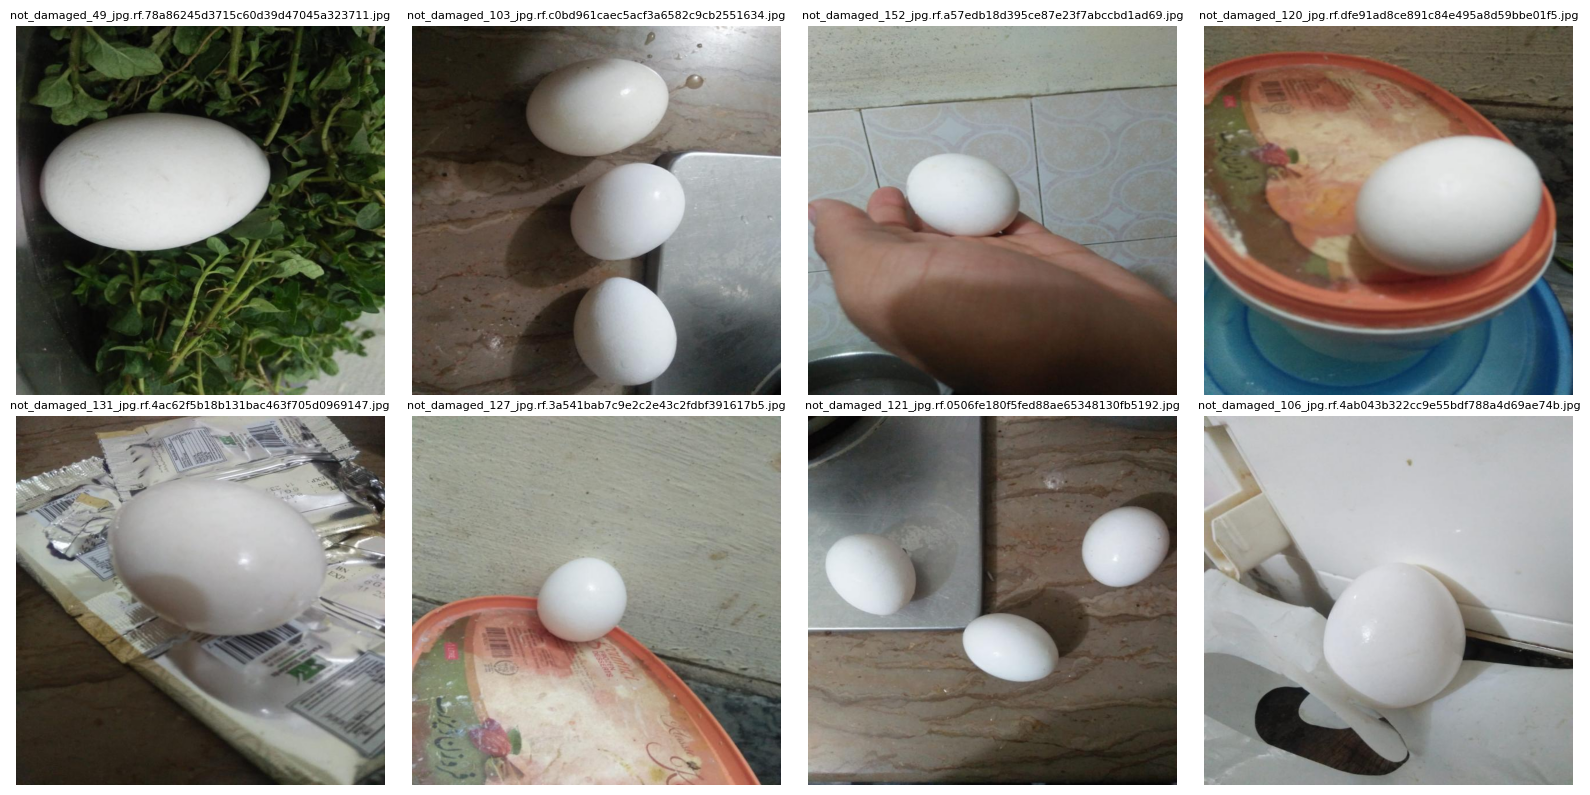

In [9]:
# Preview a few images before processing the dataset.
sample_paths = random.sample(image_paths, min(8, len(image_paths)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, path in zip(axes, sample_paths):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Choose where to save the results

The results go in `/kaggle/working/task1_results`. After the notebook runs, you can download them from Kaggle's **Output** panel.

In [10]:
OUTPUT_DIR = Path("/kaggle/working/task1_results")
RAW_MASK_DIR = OUTPUT_DIR / "raw_sam_candidates"
SELECTED_MASK_DIR = OUTPUT_DIR / "selected_masks"
COMBINED_MASK_DIR = OUTPUT_DIR / "combined_masks"
OVERLAY_DIR = OUTPUT_DIR / "overlays"
VIS_DIR = OUTPUT_DIR / "visualizations"

for folder in [RAW_MASK_DIR, SELECTED_MASK_DIR, COMBINED_MASK_DIR, OVERLAY_DIR, VIS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: /kaggle/working/task1_results


## Filter for likely egg masks

SAM creates masks for all kinds of objects. This function uses simple shape measurements to rank masks that might contain eggs. It can still select parts of a hand or background, so treat the results as a first pass and check the visual previews.

Adjust the area, aspect ratio, solidity, and extent limits after looking at your images. The score helps rank masks; it is not a probability that a mask contains an egg.

In [11]:
# Initial heuristic thresholds — tune using representative training/development images.
MIN_AREA_RATIO = 0.002
MAX_AREA_RATIO = 0.65
MIN_ASPECT_RATIO = 0.40
MAX_ASPECT_RATIO = 2.50
MIN_SOLIDITY = 0.75
MIN_EXTENT = 0.35
DUPLICATE_MASK_IOU = 0.75


def calculate_shape_features(mask):
    mask_u8 = mask.astype(np.uint8)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return None

    contour = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(contour))
    if area <= 0:
        return None

    x, y, w, h = cv2.boundingRect(contour)
    perimeter = float(cv2.arcLength(contour, True))
    hull_area = float(cv2.contourArea(cv2.convexHull(contour)))

    return {
        "area": area,
        "bbox": (int(x), int(y), int(w), int(h)),
        "aspect_ratio": float(w / (h + 1e-6)),
        "solidity": float(area / (hull_area + 1e-6)),
        "extent": float(area / (w * h + 1e-6)),
        "circularity": float(4 * np.pi * area / (perimeter**2 + 1e-6))
    }


def egg_candidate_score(mask_data, image_shape):
    mask = mask_data["segmentation"].astype(bool)
    features = calculate_shape_features(mask)
    if features is None:
        return None

    height, width = image_shape[:2]
    area_ratio = features["area"] / float(height * width)
    aspect = features["aspect_ratio"]
    solidity = features["solidity"]
    extent = features["extent"]
    circularity = features["circularity"]

    if not (MIN_AREA_RATIO <= area_ratio <= MAX_AREA_RATIO):
        return None
    if not (MIN_ASPECT_RATIO <= aspect <= MAX_ASPECT_RATIO):
        return None
    if solidity < MIN_SOLIDITY or extent < MIN_EXTENT:
        return None

    aspect_score = np.exp(-(np.log(aspect) ** 2) / (2 * 0.65**2))
    solidity_score = np.clip(solidity, 0, 1)
    extent_score = np.clip(extent / 0.85, 0, 1)
    circularity_score = np.clip(circularity / 0.85, 0, 1)
    sam_iou = float(mask_data.get("predicted_iou", 0))
    stability = float(mask_data.get("stability_score", 0))

    score = (
        0.25 * aspect_score +
        0.15 * solidity_score +
        0.15 * extent_score +
        0.10 * circularity_score +
        0.20 * sam_iou +
        0.15 * stability
    )

    features["area_ratio"] = float(area_ratio)
    return float(score), features

In [12]:
def binary_mask_iou(mask1, mask2):
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    return float(intersection / (union + 1e-6))


def remove_duplicate_masks(candidates, iou_threshold=DUPLICATE_MASK_IOU):
    candidates = sorted(candidates, key=lambda item: item["score"], reverse=True)
    kept = []

    for candidate in candidates:
        is_duplicate = any(
            binary_mask_iou(candidate["mask"], existing["mask"]) > iou_threshold
            for existing in kept
        )
        if not is_duplicate:
            kept.append(candidate)

    return kept


def segment_eggs(image):
    image_rgb = np.asarray(image.convert("RGB"))
    raw_masks = mask_generator.generate(image_rgb)

    candidates = []
    for mask_data in raw_masks:
        scored = egg_candidate_score(mask_data, image_rgb.shape)
        if scored is None:
            continue

        score, features = scored
        candidates.append({
            "mask": mask_data["segmentation"].astype(bool),
            "score": score,
            "features": features,
            "predicted_iou": float(mask_data.get("predicted_iou", 0)),
            "stability_score": float(mask_data.get("stability_score", 0))
        })

    selected = remove_duplicate_masks(candidates)
    return image_rgb, raw_masks, selected

## Run segmentation across the dataset

The loop keeps each image's subfolder path so files with the same name won't overwrite one another. It saves the original masks as compressed NumPy files and the selected and combined masks as PNGs.

In [13]:
records = []
failures = []

for image_path in tqdm(image_paths, desc="SAM segmentation"):
    relative_path = image_path.relative_to(INPUT_DIR)
    stem = image_path.stem
    subdir = relative_path.parent

    raw_dir = RAW_MASK_DIR / subdir
    selected_dir = SELECTED_MASK_DIR / subdir
    combined_dir = COMBINED_MASK_DIR / subdir
    overlay_dir = OVERLAY_DIR / subdir
    vis_dir = VIS_DIR / subdir

    for folder in [raw_dir, selected_dir, combined_dir, overlay_dir, vis_dir]:
        folder.mkdir(parents=True, exist_ok=True)

    try:
        image = Image.open(image_path).convert("RGB")
        image_rgb, raw_masks, selected = segment_eggs(image)

        # Keep all raw SAM masks so they can be filtered again later.
        if raw_masks:
            raw_stack = np.stack([
                item["segmentation"].astype(np.uint8) for item in raw_masks
            ])
            np.savez_compressed(raw_dir / f"{stem}_raw.npz", masks=raw_stack)
        else:
            np.savez_compressed(
                raw_dir / f"{stem}_raw.npz",
                masks=np.empty((0, image_rgb.shape[0], image_rgb.shape[1]), dtype=np.uint8)
            )

        # Save each selected mask as its own image.
        for i, candidate in enumerate(selected, start=1):
            mask_u8 = candidate["mask"].astype(np.uint8) * 255
            cv2.imwrite(str(selected_dir / f"{stem}_candidate_{i:02d}.png"), mask_u8)

        # Combine the selected masks into one binary image.
        combined = np.zeros(image_rgb.shape[:2], dtype=np.uint8)
        for candidate in selected:
            combined[candidate["mask"]] = 255

        cv2.imwrite(str(combined_dir / f"{stem}_mask.png"), combined)

        # Create a colored overlay to make the masks easier to inspect.
        overlay = image_rgb.copy()
        rng = np.random.default_rng(SEED)
        for candidate in selected:
            color = rng.integers(60, 256, size=3, dtype=np.uint8)
            mask = candidate["mask"]
            overlay[mask] = (
                0.5 * overlay[mask].astype(np.float32) +
                0.5 * color.astype(np.float32)
            ).astype(np.uint8)

            contours, _ = cv2.findContours(
                mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            cv2.drawContours(overlay, contours, -1, (255, 0, 0), 2)

        cv2.imwrite(
            str(overlay_dir / f"{stem}_overlay.png"),
            cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
        )

        # Save a side-by-side view for a quick visual check.
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(image_rgb)
        axes[0].set_title("Original")
        axes[1].imshow(combined, cmap="gray", vmin=0, vmax=255)
        axes[1].set_title("Selected mask union")
        axes[2].imshow(overlay)
        axes[2].set_title(f"Candidates: {len(selected)}")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        fig.savefig(vis_dir / f"{stem}_visualization.png", dpi=120, bbox_inches="tight")
        plt.close(fig)

        records.append({
            "image": str(relative_path),
            "width": int(image_rgb.shape[1]),
            "height": int(image_rgb.shape[0]),
            "raw_sam_masks": len(raw_masks),
            "selected_candidates": len(selected),
            "selected_mask_pixels": int(np.count_nonzero(combined)),
            "status": "success",
            "error": ""
        })

    except Exception as exc:
        failures.append({"image": str(relative_path), "error": repr(exc)})
        records.append({
            "image": str(relative_path),
            "width": None,
            "height": None,
            "raw_sam_masks": None,
            "selected_candidates": None,
            "selected_mask_pixels": None,
            "status": "failed",
            "error": repr(exc)
        })

    if DEVICE == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(records)
results_df.to_csv(OUTPUT_DIR / "segmentation_results.csv", index=False)
pd.DataFrame(failures, columns=["image", "error"]).to_csv(
    OUTPUT_DIR / "failed_images.csv", index=False
)

print("Finished.")
print("Successful:", int((results_df["status"] == "success").sum()))
print("Failed:", int((results_df["status"] == "failed").sum()))

SAM segmentation:   0%|          | 0/110 [00:00<?, ?it/s]

Finished.
Successful: 110
Failed: 0


## Review a sample of the results

Check whether each mask covers the whole egg, includes parts of the hand or background, joins nearby eggs together, or misses an egg. Use what you find to adjust the filters.

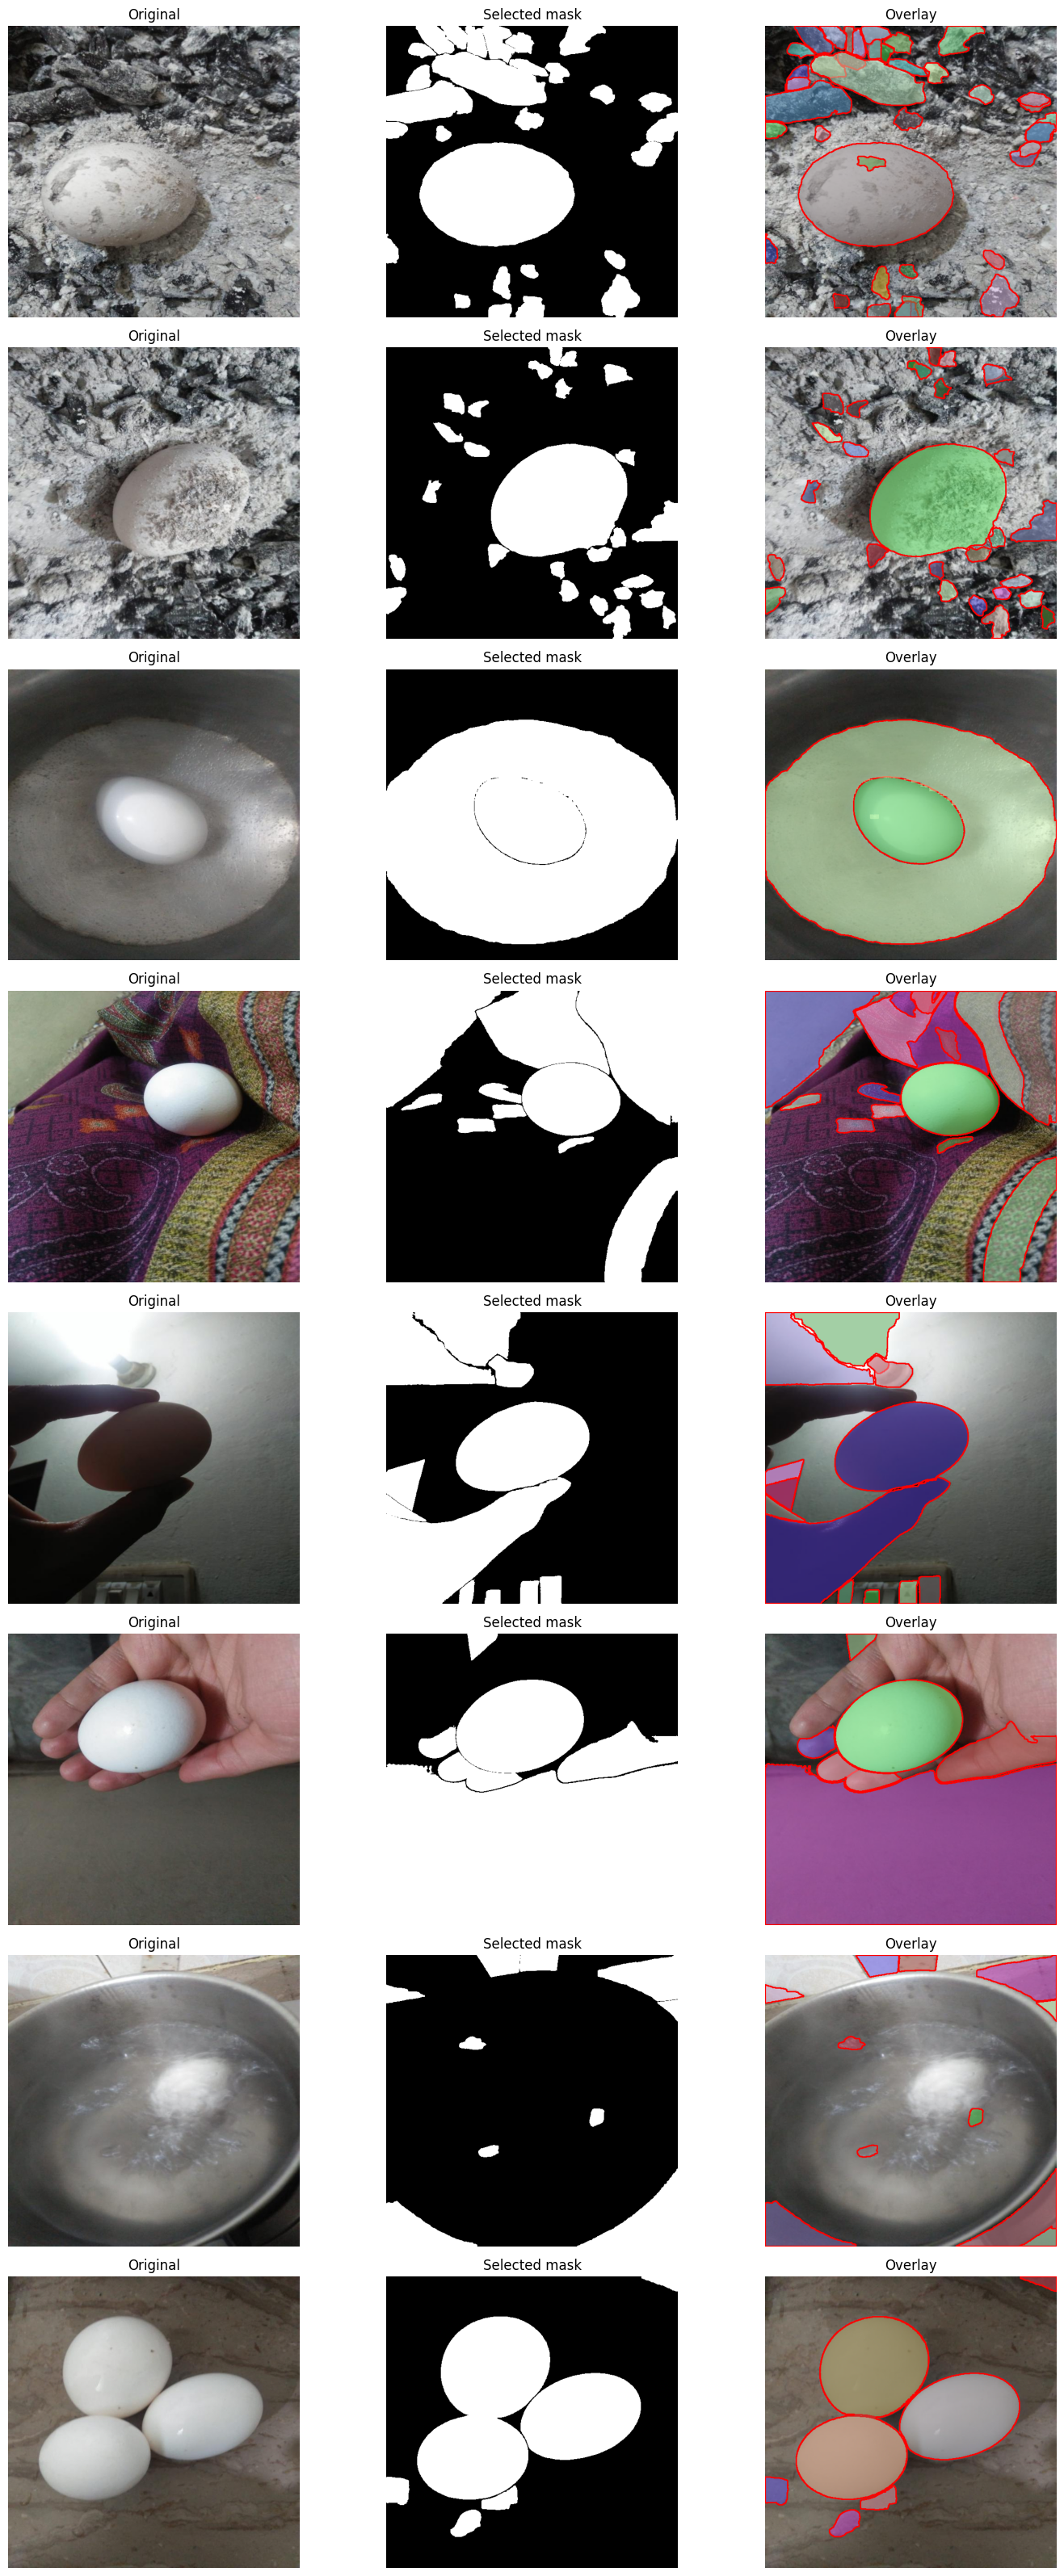

In [14]:
successful = results_df[results_df["status"] == "success"].copy()

if len(successful) == 0:
    print("No successful images to display.")
else:
    sample = successful.sample(min(8, len(successful)), random_state=SEED)
    fig, axes = plt.subplots(len(sample), 3, figsize=(15, 4 * len(sample)))
    if len(sample) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, (_, row) in enumerate(sample.iterrows()):
        rel = Path(row["image"])
        original = np.asarray(Image.open(INPUT_DIR / rel).convert("RGB"))
        mask_path = COMBINED_MASK_DIR / rel.parent / f"{rel.stem}_mask.png"
        overlay_path = OVERLAY_DIR / rel.parent / f"{rel.stem}_overlay.png"

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        overlay_bgr = cv2.imread(str(overlay_path))
        overlay = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

        axes[row_idx, 0].imshow(original)
        axes[row_idx, 0].set_title("Original")
        axes[row_idx, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
        axes[row_idx, 1].set_title("Selected mask")
        axes[row_idx, 2].imshow(overlay)
        axes[row_idx, 2].set_title("Overlay")

        for ax in axes[row_idx]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

,raw_sam_masks,selected_candidates,selected_mask_pixels
count,110.000000,110.000000,110.000000
mean,76.990909,13.209091,156792.518182
std,98.359432,12.574253,95233.334385
min,13.000000,1.000000,34246.000000
25%,29.000000,6.250000,82806.500000
50%,38.500000,9.000000,130087.500000
75%,66.500000,14.000000,215401.250000
max,504.000000,60.000000,406262.000000


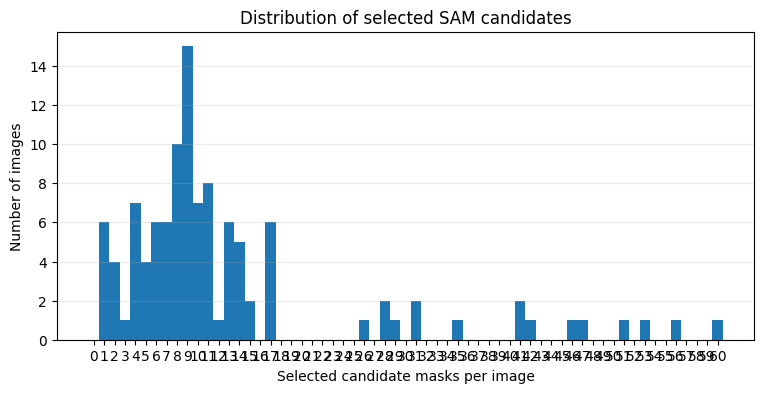

Images with zero selected candidates: 0


In [16]:
# Summarize the results and show how many candidates were found per image.
successful = results_df[results_df["status"] == "success"]

display(successful[[
    "raw_sam_masks", "selected_candidates", "selected_mask_pixels"
]].describe())

if len(successful):
    max_count = int(successful["selected_candidates"].max())
    bins = np.arange(-0.5, max_count + 1.5, 1)
    plt.figure(figsize=(9, 4))
    plt.hist(successful["selected_candidates"], bins=bins)
    plt.xlabel("Selected candidate masks per image")
    plt.ylabel("Number of images")
    plt.title("Distribution of selected SAM candidates")
    plt.xticks(range(max_count + 1))
    plt.grid(axis="y", alpha=0.25)
    plt.show()

print("Images with zero selected candidates:",
      int((successful["selected_candidates"] == 0).sum()))

## Package the results for download

The notebook creates `/kaggle/working/task1_results.zip`. When it finishes, download the archive from Kaggle's **Output** panel.

In [17]:
ZIP_BASE = "/kaggle/working/task1_results"
ZIP_PATH = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/kaggle/working",
    base_dir="task1_results"
)

print("ZIP created:", ZIP_PATH)
print("Size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))

ZIP created: /kaggle/working/task1_results.zip
Size (MB): 97.41


## Task 1 review checklist

- [ ] Check that the notebook found the expected number of images.
- [ ] Check that SAM finished on all intended images.
- [ ] Review at least 20 results, including some difficult examples.
- [ ] Look for images with no selected masks and for false detections.
- [ ] Adjust the filters using representative development images.
- [ ] Keep the original masks and note the final settings.
- [ ] Manually inspect masks before treating them as ground truth.

**For the report:** These SAM masks are pseudo-labels. When you evaluate against them in Task 3, explain that the scores show agreement with SAM and may differ from manually drawn egg boundaries.